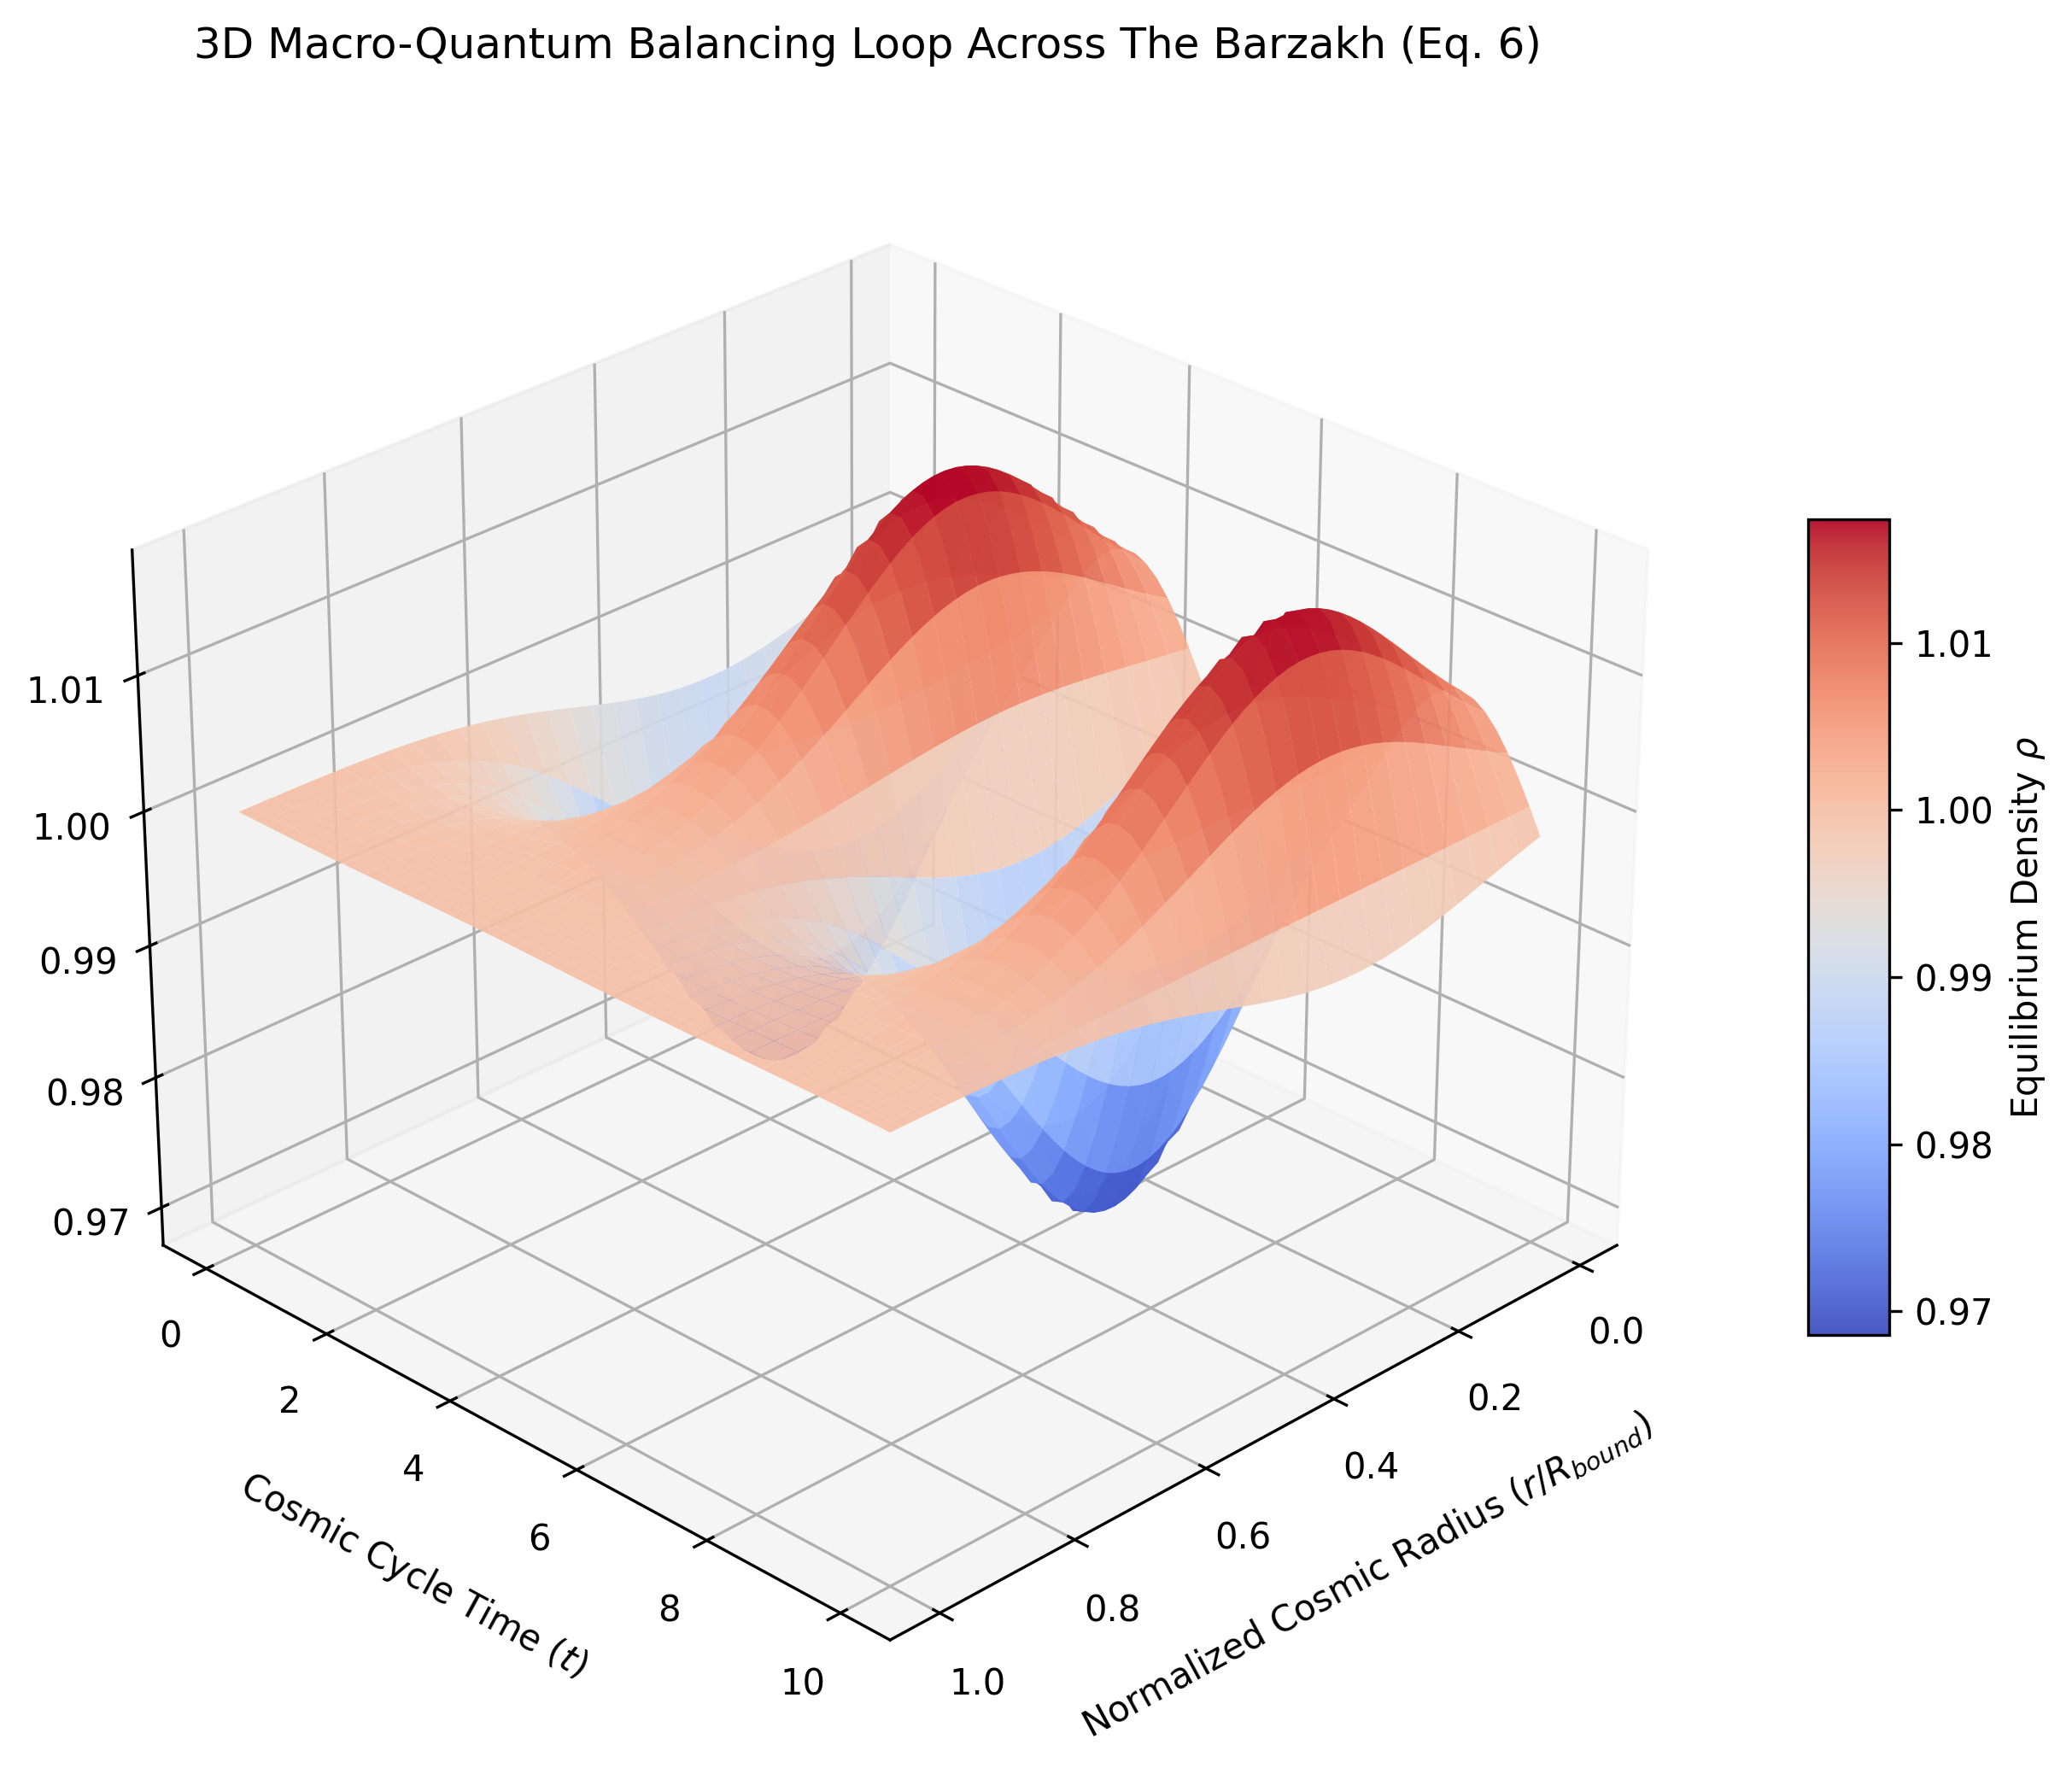

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# شبكة الزمكان المغلق (نصف القطر الكوني المعياري r والزمن الكوني t)
r = np.linspace(0.01, 1.0, 60)  # 0 = مركز العناقيد، 1 = الحدود الخارجية
t = np.linspace(0, 10, 60)      # دورات التوازن الماكرو-كمومية
R, T = np.meshgrid(r, t)

# معدل التخليق النجمي (يتركز في العناقيد r < 0.5)
Gamma_stars = 0.45 * np.exp(-((R - 0.3)**2) / 0.08) * (1 + 0.2 * np.sin(2 * np.pi * T / 5))

# معدل إعادة التدوير عبر الثقوب السوداء (يعمل بفرق طور للحفاظ على الاتزان عند البرزخ)
Gamma_BH = 0.45 * np.exp(-((R - 0.3)**2) / 0.08) * (1 + 0.2 * np.sin(2 * np.pi * T / 5 - 0.35))

# الكثافة الصافية المتوازنة للمائع الفائق (المعادلة 6)
rho_equilibrium = 1.0 + np.cumsum(Gamma_BH - Gamma_stars, axis=0) * (t[1] - t[0])

fig = plt.figure(figsize=(10, 7), dpi=300)
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(R, T, rho_equilibrium, cmap='coolwarm', edgecolor='none', alpha=0.92)

ax.set_title('3D Macro-Quantum Balancing Loop Across The Barzakh (Eq. 6)', fontsize=12, pad=15)
ax.set_xlabel('Normalized Cosmic Radius ($r / R_{bound}$)', fontsize=10, labelpad=10)
ax.set_ylabel('Cosmic Cycle Time ($t$)', fontsize=10, labelpad=10)
ax.set_zlabel('Normalized Substrate Density ($\\rho / \\rho_{crit}$)', fontsize=10, labelpad=10)
fig.colorbar(surf, shrink=0.5, aspect=10, label='Equilibrium Density $\\rho$')
ax.view_init(elev=28, azim=45)

plt.tight_layout()
plt.savefig('sim3_3d_balancing_loop.png', dpi=300)
plt.show()